In [1]:
import pandas as pd
from snownlp import SnowNLP
import jieba
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.decomposition import LatentDirichletAllocation as LDA
from sklearn.feature_extraction.text import CountVectorizer
from matplotlib import font_manager
from snownlp import SnowNLP
import seaborn as sns
import gensim
from gensim import corpora  
import pyLDAvis  
import pyLDAvis.gensim as gensimvis 
import matplotlib.font_manager as fm
import os
from matplotlib.colors import ListedColormap, BoundaryNorm
import geopandas as gpd

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

with open('/home/mw/input/data_total74037403/个人角度数据集/停用词表.txt', 'r', encoding='utf-8') as f:
    stop_words = set(f.read().splitlines())

data = pd.read_csv('/home/mw/input/data_total74037403/个人角度数据集/weibo_data.csv', encoding='utf-8')

d:\anaconda\Lib\site-packages\geopandas\_compat.py:7: DeprecationWarning: The 'shapely.geos' module is deprecated, and will be removed in a future version. All attributes of 'shapely.geos' are available directly from the top-level 'shapely' namespace (since shapely 2.0.0).
  import shapely.geos


In [2]:
def preprocess_text(text):
    words = jieba.cut(text)
    return ' '.join([word for word in words if word not in stop_words])

data['内容'] = data['内容'].apply(preprocess_text)
data['tokenized'] = data['内容'].apply(lambda x: x.split())

 
def sentiment_label(score, neg_threshold=0.33, pos_threshold=0.66):  
    if score < neg_threshold:  
        return "负面"  
    elif score >= pos_threshold:
        return "正面"  
    else:  
        return "中立"  

comment_list = data['内容'].tolist()  
sentiments = []  
for comment in comment_list:  
    s = SnowNLP(str(comment))  
    sentiments.append(sentiment_label(s.sentiments))  

data['情感倾向'] = sentiments  

#  标记“是否提及平权”  
equity_keywords = ["数字鸿沟", "教育公平", "可及性", "偏远地区", "公益", "普惠", "资源分配"]  
def contains_equity_kw(token_list, kw_list):  
    return any(kw in token_list for kw in kw_list)  

data['是否提及平权'] = data['tokenized'].apply(  
    lambda tokens: 1 if contains_equity_kw(tokens, equity_keywords) else 0  
)  

#  LDA主题建模  
processed_comments = data['tokenized'].tolist()  
dictionary = corpora.Dictionary(processed_comments)  
dictionary.filter_extremes(no_below=5, no_above=0.5)

corpus = [dictionary.doc2bow(text) for text in processed_comments]  
num_topics = 10
lda_model = gensim.models.LdaModel(  
    corpus=corpus,  
    id2word=dictionary,  
    num_topics=num_topics,  
    random_state=42,  
    passes=10,
    alpha='auto',
    per_word_topics=True
)

print("==== LDA模型主题Top词 ====")  
for idx, topic in lda_model.print_topics(num_topics=num_topics, num_words=10):  
    print(f"主题{idx}: {topic}")  


dominant_topics = []  
for i, row_list in enumerate(lda_model[corpus]):  
    topic_probs = row_list[0]  # [(topic_id, prob), ...]  
    dominant_topic = sorted(topic_probs, key=lambda x: x[1], reverse=True)[0][0]  
    dominant_topics.append(dominant_topic)  

data['主要主题'] = dominant_topics  



# 情感影响力  
def get_sentiment_impact(row):  
    impact = row['转发'] + row['评论']   
    if row['情感倾向'] == '正面':  
        return impact  
    elif row['情感倾向'] == '负面':  
        return -impact  
    else:  
        return 0  

if '转发' in data.columns and '评论' in data.columns:  
    data['情感影响力'] = data.apply(get_sentiment_impact, axis=1)  
    impact_by_topic = data.groupby('主要主题')['情感影响力'].sum().sort_values(ascending=False)  
    print("====按主题汇总的情感影响力====")  
    print(impact_by_topic)  

def extract_concerns(token_list, concern_dict):  
    concerns_mentioned = set()  
    for concern_category, keywords in concern_dict.items():  
        if any(kw in token_list for kw in keywords):  
            concerns_mentioned.add(concern_category)  
    return concerns_mentioned  

# 担忧词典  
concern_dict = {
    "数据隐私": ["隐私", "隐私保护", "个人信息", "信息泄露", "私人信息"],  
    "数据安全": ["数据安全", "信息安全", "网络安全", "泄露风险"],  
    "治理": ["治理", "监管", "管理", "管控", "审核", "政策监管"],  
    "过度依赖": ["过度依赖", "过分依赖", "过度使用", "沉迷"],
    "潜在偏见": ["偏见", "歧视", "不公平", "算法偏见", "算法歧视"],
}

positive_dict = {
    "防诈骗": ["反诈骗", "防诈骗", "识别诈骗", "阻止诈骗", "防止上当", "诈骗预警", "诈骗识别"],  
    "效率便捷": ["效率", "快捷", "便利", "省时", "自动化", "节约时间", "加速"],  
    "创造力提升": ["激发灵感", "创意", "新点子", "想法", "创新"],  
    "社会价值": ["改善生活", "解决问题", "帮助", "公益", "助力", "赋能"]  
}  

data['担忧集合'] = data['tokenized'].apply(lambda x: extract_concerns(x, concern_dict))  
for cat in concern_dict:  
    data[f"担忧_{cat}"] = data['担忧集合'].apply(lambda cset: 1 if cat in cset else 0)  

concern_counts = {cat: data[f"担忧_{cat}"].sum() for cat in concern_dict.keys()}  
concern_counts = dict(sorted(concern_counts.items(), key=lambda x: x[1], reverse=True))  

labels_concerns = list(concern_counts.keys())  
sizes_concerns = list(concern_counts.values())  



rows = []  
for cat in concern_dict.keys():  
    subset = data[data[f"担忧_{cat}"] == 1]  
    sentiment_count = subset['情感倾向'].value_counts(normalize=True) * 100  
    rows.append([  
        cat,  
        sentiment_count.get('负面', 0),  
        sentiment_count.get('中立', 0),  
        sentiment_count.get('正面', 0)  
    ])  

df_res = pd.DataFrame(rows, columns=["担忧类型", "负面(%)", "中立(%)", "正面(%)"]).sort_values(by="负面(%)", ascending=False)  
print("=== 担忧类型 vs. 情感倾向 ===")  
print(df_res)  

data['AI正面集合'] = data['tokenized'].apply(lambda x: extract_concerns(x, positive_dict))  
for cat in positive_dict:  
    data[f"AI正面_{cat}"] = data['AI正面集合'].apply(lambda cset: 1 if cat in cset else 0)  

pos_counts = {cat: data[f"AI正面_{cat}"].sum() for cat in positive_dict.keys()}  
pos_counts = dict(sorted(pos_counts.items(), key=lambda x: x[1], reverse=True))  

print("\n【AI正面主题出现次数】")  
for k, v in pos_counts.items():  
    print(f"{k} : {v} 条评论提及")  

labels_pos = list(pos_counts.keys())  
sizes_pos = list(pos_counts.values())  



# 11. 正面主题 × 情感
rows_positive = []
for cat in positive_dict.keys():
    subset = data[data[f"AI正面_{cat}"] == 1]
    sentiment_count = subset['情感倾向'].value_counts(normalize=True) * 100
    rows_positive.append([
        cat,  
        sentiment_count.get('负面', 0),
        sentiment_count.get('中立', 0),
        sentiment_count.get('正面', 0)
    ])

df_pos = pd.DataFrame(rows_positive, columns=["正面主题", "负面(%)", "中立(%)", "正面(%)"]).sort_values(by="负面(%)", ascending=False)
print("\n=== 正面主题 vs. 情感倾向 ===")
print(df_pos)

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\fwq81\AppData\Local\Temp\jieba.cache
Loading model cost 0.431 seconds.
Prefix dict has been built successfully.


==== LDA模型主题Top词 ====
主题0: 0.027*"技术" + 0.025*"发展" + 0.015*"中国" + 0.013*"创新" + 0.011*"企业" + 0.011*"产业" + 0.010*"领域" + 0.010*"数字" + 0.010*"未来" + 0.009*"数据"
主题1: 0.036*"生成" + 0.026*"视频" + 0.024*"内容" + 0.012*"游戏" + 0.011*"技术" + 0.011*"创作" + 0.008*"图片" + 0.007*"http" + 0.007*"作品" + 0.007*"用户"
主题2: 0.025*"功能" + 0.020*"用户" + 0.019*"苹果" + 0.016*"手机" + 0.012*"推出" + 0.012*"支持" + 0.010*"提供" + 0.008*"设备" + 0.008*"性能" + 0.007*"体验"
主题3: 0.029*"亲子鉴定" + 0.019*"服务" + 0.019*"机构" + 0.014*"鉴定" + 0.012*"检测" + 0.011*"中心" + 0.009*"管理" + 0.008*"信息" + 0.008*"提供" + 0.007*"标识"
主题4: 0.019*"市场" + 0.016*"增长" + 0.011*"公司" + 0.011*"伟达" + 0.010*"芯片" + 0.010*"英" + 0.008*"亿美元" + 0.008*"需求" + 0.008*"2024" + 0.007*"亿元"
主题5: 0.020*"教育" + 0.014*"学生" + 0.010*"文化" + 0.008*"教学" + 0.007*"教师" + 0.007*"网络" + 0.006*"学习" + 0.006*"实践" + 0.005*"课程" + 0.005*"发展"
主题6: 0.024*"公司" + 0.022*"月" + 0.019*"美国" + 0.016*"日" + 0.014*"OpenAI" + 0.012*"中国" + 0.007*"全球" + 0.007*"称" + 0.007*"科技" + 0.006*"机器人"
主题7: 0.014*"模型" + 0.009*"数据" + 0.009*"生

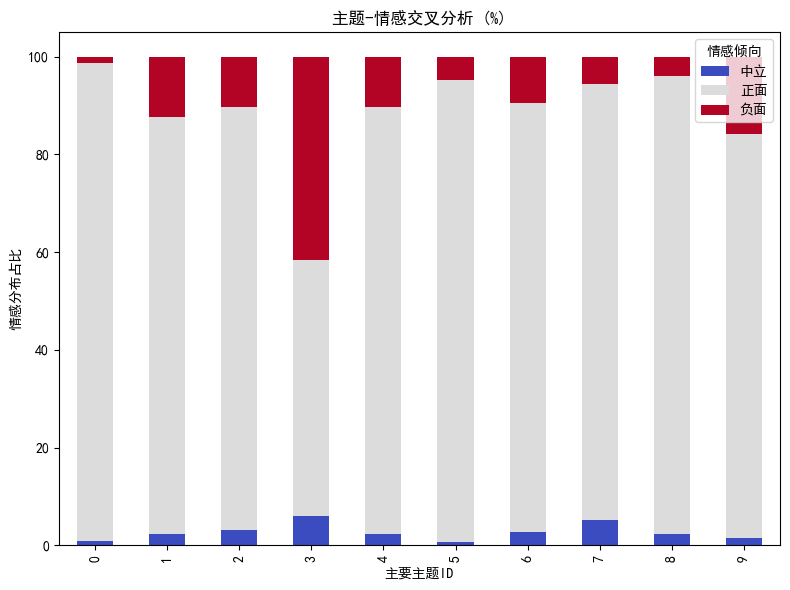

In [9]:
# 主题-情感交叉分析堆叠柱状图
cross_tab = pd.crosstab(data['主要主题'], data['情感倾向'], normalize='index') * 100  
cross_tab.plot(kind='bar', stacked=True, figsize=(8,6), colormap='coolwarm')  
plt.title("主题-情感交叉分析 (%)")  
plt.xlabel("主要主题ID")  
plt.ylabel("情感分布占比")  
plt.legend(title="情感倾向")  
plt.tight_layout()  
plt.show()  



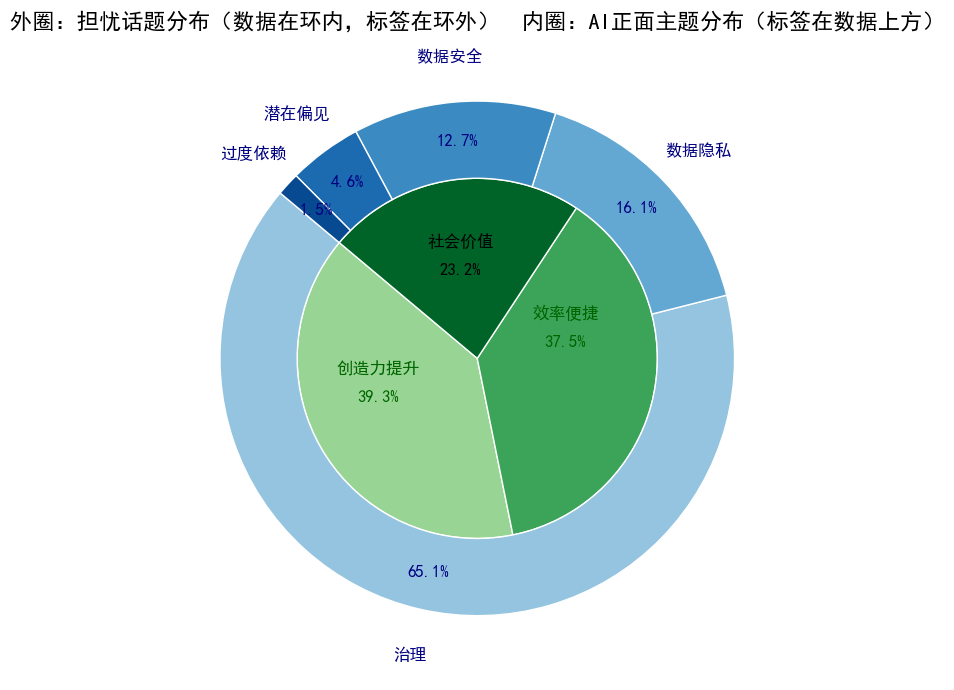

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# 过滤掉“防诈骗”主题及其数据
labels_pos_filtered = []
sizes_pos_filtered = []
for label, size in zip(labels_pos, sizes_pos):
    if label != "防诈骗":
        labels_pos_filtered.append(label)
        sizes_pos_filtered.append(size)

# 生成绿色渐变（内圈-正面主题，实心圆）
green_cmap = plt.get_cmap('Greens')
colors_pos = [green_cmap(0.4 + 0.5 * i / max(1, len(sizes_pos_filtered)-1)) for i in range(len(sizes_pos_filtered))]
# 生成蓝色渐变（外圈-担忧）
blue_cmap = plt.get_cmap('Blues')
colors_concerns = [blue_cmap(0.4 + 0.5 * i / max(1, len(sizes_concerns)-1)) for i in range(len(sizes_concerns))]

fig, ax = plt.subplots(figsize=(7, 7))

# 内圈：AI正面主题分布（绿色实心圆，不直接显示label和百分比，手动添加）
wedges2, _ = ax.pie(
    sizes_pos_filtered,
    labels=None,
    autopct=None,
    radius=0.7,
    startangle=140,
    wedgeprops=dict(width=0.7, edgecolor='w'),
    colors=colors_pos
)

for i, w in enumerate(wedges2):
    ang = (w.theta2 + w.theta1) / 2.
    # “效率便捷”向左上调整
    if labels_pos_filtered[i] == "效率便捷":
        offset_r = 0.45
        offset_y = 0.15  # 向上偏移
        offset_x = -0.10 # 向左偏移
    elif labels_pos_filtered[i] == "社会价值":
        offset_r = 0.45
        offset_y = -0.10  # 向下偏移
        offset_x = 0
    else:
        offset_r = 0.45
        offset_y = 0.08
        offset_x = 0
    x_data = np.cos(np.deg2rad(ang)) * offset_r + offset_x
    y_data = np.sin(np.deg2rad(ang)) * offset_r + offset_y
    percent = sizes_pos_filtered[i] / sum(sizes_pos_filtered) * 100
    font_color = 'black' if labels_pos_filtered[i] == "社会价值" else 'darkgreen'
    # 数据
    ax.text(
        x_data, y_data,
        f"{percent:.1f}%",
        ha='center', va='center',
        fontsize=12, color=font_color, fontweight='bold'
    )
    # 标签在数据正上方
    ax.text(
        x_data, y_data + 0.08,
        labels_pos_filtered[i],
        ha='center', va='bottom',
        fontsize=12, color=font_color
    )

# 外圈：担忧话题分布（蓝色渐变环，数据在环内，标签在环外）
wedges1, _ = ax.pie(
    sizes_concerns,
    labels=None,
    autopct=None,
    radius=1.0,
    startangle=140,
    wedgeprops=dict(width=0.3, edgecolor='w'),
    colors=colors_concerns
)

for i, w in enumerate(wedges1):
    ang = (w.theta2 + w.theta1) / 2.
    # 数据（百分比）放在环内
    x_data = np.cos(np.deg2rad(ang)) * 0.85
    y_data = np.sin(np.deg2rad(ang)) * 0.85
    percent = sizes_concerns[i] / sum(sizes_concerns) * 100
    ax.text(
        x_data, y_data,
        f"{percent:.1f}%",
        ha='center', va='center',
        fontsize=12, color='navy', fontweight='bold'
    )
    # 标签放在环外
    x_label = np.cos(np.deg2rad(ang)) * 1.18
    y_label = np.sin(np.deg2rad(ang)) * 1.18
    ax.text(
        x_label, y_label,
        labels_concerns[i],
        ha='center', va='center',
        fontsize=12, color='navy'
    )

plt.title("外圈：担忧话题分布（数据在环内，标签在环外）  内圈：AI正面主题分布（标签在数据上方）", fontsize=16)
plt.tight_layout()
plt.show()

In [32]:
import gensim
from gensim import corpora

def lda_topic_analysis(token_lists, num_topics=5, num_words=10):
    dictionary = corpora.Dictionary(token_lists)
    dictionary.filter_extremes(no_below=3, no_above=0.5)
    corpus = [dictionary.doc2bow(text) for text in token_lists]
    lda_model = gensim.models.LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        passes=10,
        alpha='auto',
        per_word_topics=True
    )
    topics = lda_model.print_topics(num_topics=num_topics, num_words=num_words)
    return topics

# 正面情感评论主题分析
pos_tokens = data[data['情感倾向'] == '正面']['tokenized'].tolist()
print("=== 正面情感评论主题分析 ===")
pos_topics = lda_topic_analysis(pos_tokens, num_topics=5, num_words=10)
for idx, topic in pos_topics:
    print(f"主题{idx}: {topic}")

# 负面情感评论主题分析
neg_tokens = data[data['情感倾向'] == '负面']['tokenized'].tolist()
print("\n=== 负面情感评论主题分析 ===")
neg_topics = lda_topic_analysis(neg_tokens, num_topics=5, num_words=10)
for idx, topic in neg_topics:
    print(f"主题{idx}: {topic}")

=== 正面情感评论主题分析 ===
主题0: 0.013*"发展" + 0.011*"教育" + 0.009*"技术" + 0.008*"中国" + 0.007*"创新" + 0.007*"学生" + 0.006*"数字" + 0.005*"服务" + 0.005*"产业" + 0.005*"文化"
主题1: 0.018*"公司" + 0.016*"美国" + 0.011*"月" + 0.011*"OpenAI" + 0.009*"苹果" + 0.007*"全球" + 0.007*"日" + 0.007*"中国" + 0.006*"称" + 0.005*"谷歌"
主题2: 0.027*"模型" + 0.014*"技术" + 0.011*"生成" + 0.010*"数据" + 0.010*"智能" + 0.008*"用户" + 0.007*"提供" + 0.006*"能力" + 0.006*"DeepSeek" + 0.005*"训练"
主题3: 0.007*"生成" + 0.004*"检测" + 0.003*"食物" + 0.003*"亲子鉴定" + 0.003*"…" + 0.002*"人类" + 0.002*"视频" + 0.002*"内容" + 0.002*"作品" + 0.002*"时间"
主题4: 0.010*"市场" + 0.008*"增长" + 0.007*"公司" + 0.007*"中国" + 0.007*"科技" + 0.006*"机器人" + 0.006*"技术" + 0.006*"算力" + 0.005*"月" + 0.005*"芯片"

=== 负面情感评论主题分析 ===
主题0: 0.062*"标识" + 0.045*"生成" + 0.040*"内容" + 0.036*"合成" + 0.021*"办法" + 0.021*"添加" + 0.017*"师" + 0.015*"提示" + 0.014*"发布" + 0.014*"月"
主题1: 0.058*"亲子鉴定" + 0.030*"机构" + 0.027*"鉴定" + 0.013*"样本" + 0.013*"中心" + 0.013*"检测" + 0.011*"地址" + 0.009*"咨询" + 0.009*"提供" + 0.009*"法医"
主题2: 0.023*"内容" + 0.02

In [34]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pyecharts import options as opts
from pyecharts.charts import Map


=== 性别维度分析（横向双向柱形图，男女同态度对齐，自定义渐变色&更紧凑间距） ===


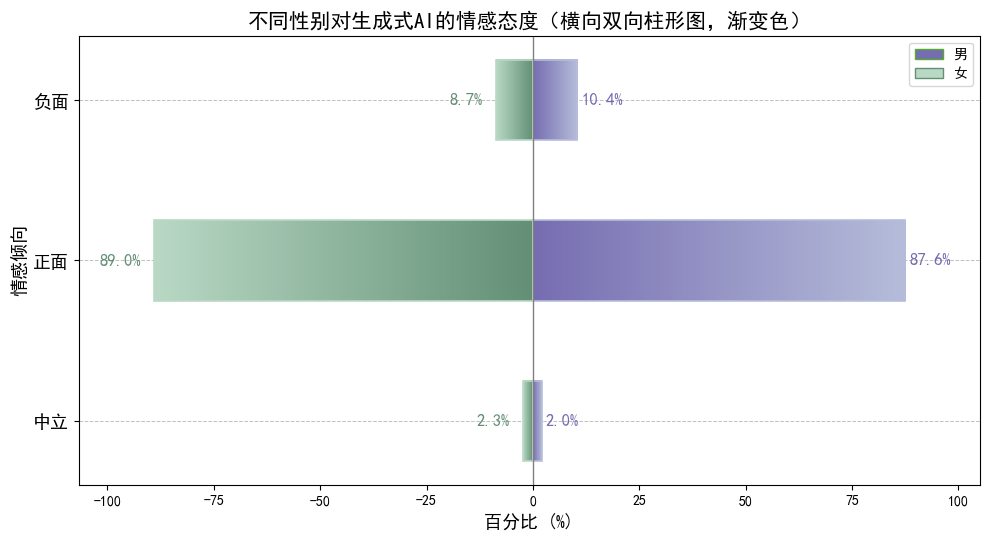

In [77]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

print("\n=== 性别维度分析（横向双向柱形图，男女同态度对齐，自定义渐变色&更紧凑间距） ===")
gender_data = data[data['性别'] != '未知'].copy()
if len(gender_data) > 0:
    import matplotlib.patches as mpatches

    gender_sentiment = pd.crosstab(gender_data['性别'], gender_data['情感倾向'], normalize='index') * 100
    genders = gender_sentiment.index.tolist()
    sentiments = gender_sentiment.columns.tolist()
    y = np.arange(len(sentiments))
    height = 0.5  # 更紧凑

    fig, ax = plt.subplots(figsize=(10, 5.5))

    # 获取数据
    male_vals = gender_sentiment.loc['男'] if '男' in genders else [0]*len(sentiments)
    female_vals = gender_sentiment.loc['女'] if '女' in genders else [0]*len(sentiments)

    def get_gradient_rect(ax, x, y, width, height, color1, color2, orientation='horizontal'):
        from matplotlib.transforms import Bbox
        import numpy as np
        from matplotlib.colors import to_rgba

        # 创建渐变色图片
        if orientation == 'horizontal':
            grad = np.linspace(0, 1, 256).reshape(1, -1)
        else:
            grad = np.linspace(0, 1, 256).reshape(-1, 1)
        grad = np.vstack((grad, grad))

        # 颜色插值
        c1 = np.array(to_rgba(color1))
        c2 = np.array(to_rgba(color2))
        img = grad[..., None] * c2 + (1-grad[..., None]) * c1

        # 显示图片
        bbox = Bbox.from_bounds(x, y, width, height)
        ax.imshow(img, extent=[x, x+width, y, y+height], aspect='auto', zorder=1)

    # 男性柱子（绿色渐变 #a8e063->#3b082）
    for idx, val in enumerate(male_vals):
        if val == 0:
            continue
        y_pos = y[idx] - height/2
        get_gradient_rect(ax, 0, y_pos, val, height, '#766db1', '#b6bdda', orientation='horizontal')
        ax.add_patch(mpatches.Rectangle((0, y_pos), val, height, fill=False, edgecolor='#b6bdda', linewidth=1.2, zorder=2))
        ax.text(val + 1, y[idx], f'{val:.1f}%', va='center', ha='left', fontsize=12, color='#766db1', zorder=3)

    # 女性柱子（蓝色渐变 #89f7fe->#0052d4）
    for idx, val in enumerate(female_vals):
        if val == 0:
            continue
        y_pos = y[idx] - height/2
        get_gradient_rect(ax, -val, y_pos, val, height, '#b9d9c5', '#638f76', orientation='horizontal')
        ax.add_patch(mpatches.Rectangle((-val, y_pos), val, height, fill=False, edgecolor='#b9d9c5', linewidth=1.2, zorder=2))
        ax.text(-val - 3, y[idx], f'{val:.1f}%', va='center', ha='right', fontsize=12, color='#638f76', zorder=3)


    # 添加虚横线
    for i in range(len(sentiments)):
        ax.axhline(y=i, color='gray', linestyle='--', linewidth=0.7, alpha=0.5, zorder=0)
        
    # 其他设置
    ax.set_yticks(y)
    ax.set_yticklabels(sentiments, fontsize=13)
    ax.set_ylabel('情感倾向', fontsize=13)
    ax.set_xlabel('百分比 (%)', fontsize=13)
    ax.set_title('不同性别对生成式AI的情感态度（横向双向柱形图，渐变色）', fontsize=15)
    ax.axvline(0, color='gray', linewidth=1)
    ax.legend([
        mpatches.Patch(facecolor='#766db1', edgecolor='#56ab2f', label='男'),
        mpatches.Patch(facecolor='#b9d9c5', edgecolor='#638f76', label='女')
    ], ['男', '女'], loc='upper right')
    ax.set_ylim(-0.4, len(sentiments)-0.6)
    ax.set_xlim(-max(female_vals)*1.2, max(male_vals)*1.2)
    plt.tight_layout()
    plt.show()

In [78]:
print("\n=== 不同性别负面情绪主要担忧分布 ===")
genders = [g for g in data['性别'].unique() if g != '未知']
concern_types = list(concern_dict.keys())

for gender in genders:
    subset = data[(data['性别'] == gender) & (data['情感倾向'] == '负面')]
    print(f"\n【{gender}性用户负面情感主要担忧主题】")
    concern_counts = {cat: subset[f'担忧_{cat}'].sum() for cat in concern_types}
    sorted_concerns = sorted(concern_counts.items(), key=lambda x: x[1], reverse=True)
    for cat, count in sorted_concerns:
        print(f"{cat}: {count} 条")
    if sorted_concerns and sorted_concerns[0][1] > 0:
        main_cat = sorted_concerns[0][0]
        print(f"主题词示例（{main_cat}）: {', '.join(concern_dict[main_cat])}")
    else:
        print("无明显担忧主题。")


=== 不同性别负面情绪主要担忧分布 ===

【男性用户负面情感主要担忧主题】
治理: 438 条
数据隐私: 270 条
过度依赖: 87 条
数据安全: 76 条
潜在偏见: 47 条
主题词示例（治理）: 治理, 监管, 管理, 管控, 审核, 政策监管

【女性用户负面情感主要担忧主题】
治理: 131 条
数据隐私: 83 条
数据安全: 23 条
过度依赖: 20 条
潜在偏见: 12 条
主题词示例（治理）: 治理, 监管, 管理, 管控, 审核, 政策监管


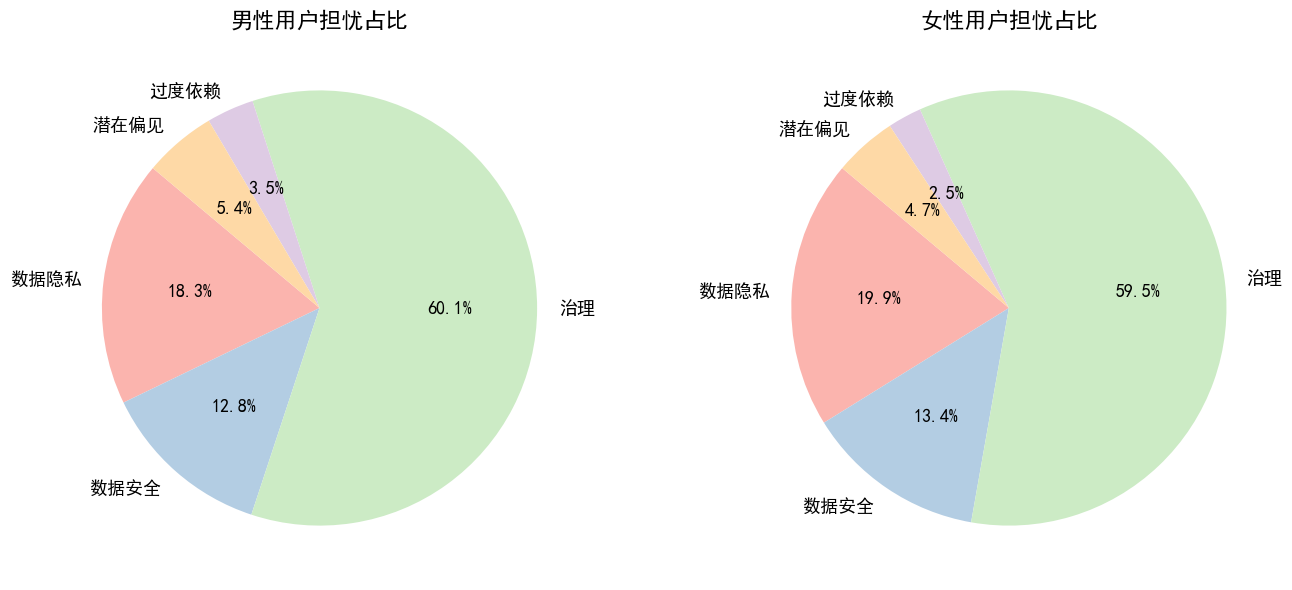

In [79]:
# 不同性别的担忧占比可视化
genders = [g for g in data['性别'].unique() if g != '未知']
concern_types = list(concern_dict.keys())

fig, axes = plt.subplots(1, len(genders), figsize=(7 * len(genders), 6))
if len(genders) == 1:
    axes = [axes]

for i, gender in enumerate(genders):
    subset = data[(data['性别'] == gender)]
    concern_counts_gender = [subset[f'担忧_{cat}'].sum() for cat in concern_types]
    total = sum(concern_counts_gender)
    if total == 0:
        axes[i].text(0.5, 0.5, '无数据', ha='center', va='center', fontsize=16)
        axes[i].set_title(f"{gender}性用户担忧占比")
        axes[i].axis('off')
        continue
    colors = plt.cm.Pastel1(range(len(concern_types)))
    wedges, texts, autotexts = axes[i].pie(
        concern_counts_gender,
        labels=concern_types,
        autopct="%1.1f%%",
        startangle=140,
        colors=colors,
        textprops={'fontsize': 13}
    )
    plt.setp(autotexts, size=13, weight="bold", color="black")
    axes[i].set_title(f"{gender}性用户担忧占比", fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

In [82]:
import gensim
from gensim import corpora

def lda_topic_analysis(token_lists, num_topics=5, num_words=10):
    dictionary = corpora.Dictionary(token_lists)
    dictionary.filter_extremes(no_below=3, no_above=0.5)
    corpus = [dictionary.doc2bow(text) for text in token_lists]
    lda_model = gensim.models.LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        random_state=42,
        passes=10,
        alpha='auto',
        per_word_topics=True
    )
    topics = lda_model.print_topics(num_topics=num_topics, num_words=num_words)
    return topics

# 男性负面评论LDA主题分析
male_tokens = data[(data['性别'] == '男') & (data['情感倾向'] == '负面')]['tokenized'].tolist()
print("=== 男性用户负面评论LDA主题分析 ===")
male_topics = lda_topic_analysis(male_tokens, num_topics=5, num_words=10)
for idx, topic in male_topics:
    print(f"主题{idx}: {topic}")

# 女性负面评论LDA主题分析
female_tokens = data[(data['性别'] == '女') & (data['情感倾向'] == '负面')]['tokenized'].tolist()
print("\n=== 女性用户负面评论LDA主题分析 ===")
female_topics = lda_topic_analysis(female_tokens, num_topics=5, num_words=10)
for idx, topic in female_topics:
    print(f"主题{idx}: {topic}")

=== 男性用户负面评论LDA主题分析 ===
主题0: 0.034*"内容" + 0.029*"标识" + 0.017*"办法" + 0.016*"合成" + 0.015*"发布" + 0.014*"月" + 0.013*"服务" + 0.012*"…" + 0.010*"模仿" + 0.010*"添加"
主题1: 0.018*"ChatGPT" + 0.016*"公司" + 0.011*"视频" + 0.010*"月" + 0.010*"三星" + 0.010*"工具" + 0.010*"用户" + 0.009*"图像" + 0.009*"模型" + 0.008*"企业"
主题2: 0.046*"用户" + 0.045*"内容" + 0.035*"国家" + 0.034*"网信" + 0.033*"办" + 0.032*"损害" + 0.031*"信息" + 0.031*"形象" + 0.031*"名誉" + 0.028*"输入"
主题3: 0.022*"信息" + 0.015*"网络" + 0.014*"服务" + 0.014*"整治" + 0.011*"专项" + 0.011*"清朗" + 0.011*"内容" + 0.010*"平台" + 0.009*"管理" + 0.009*"虚假"
主题4: 0.022*"伟达" + 0.020*"英" + 0.016*"月" + 0.014*"日" + 0.011*"公司" + 0.008*"苹果" + 0.007*"发布" + 0.006*"全球" + 0.006*"芯片" + 0.006*"机器人"

=== 女性用户负面评论LDA主题分析 ===
主题0: 0.044*"生成" + 0.042*"用户" + 0.039*"内容" + 0.036*"国家" + 0.033*"网信" + 0.032*"办" + 0.031*"信息" + 0.029*"损害" + 0.028*"形象" + 0.028*"名誉"
主题1: 0.019*"公司" + 0.015*"三星" + 0.014*"ChatGPT" + 0.012*"月" + 0.010*"生成" + 0.009*"模型" + 0.009*"企业" + 0.008*"日" + 0.008*"工具" + 0.007*"合作"
主题2: 0.021*"月" + 0.

In [98]:
# 2. 时间维度分析
print("\n=== 时间维度分析 ===")
time_data = data[data['时间'] != '未知时间'].copy()

# 解析时间，提取月份
def parse_time(time_str):
    try:
        for fmt in ['%Y/%m/%d %H:%M:%S', '%Y年%m月%d日 %H:%M']:
            try:
                return datetime.strptime(time_str, fmt)
            except:
                continue
    except:
        return None
    return None

time_data['parsed_time'] = time_data['时间'].apply(parse_time)
time_data = time_data[time_data['parsed_time'].notna()]

if len(time_data) > 0:
    time_data['年月'] = time_data['parsed_time'].dt.to_period('M').astype(str)
    
    time_sentiment = pd.crosstab(time_data['年月'], time_data['情感倾向'], normalize='index') * 100
    
    


=== 时间维度分析 ===


In [99]:
import plotly.graph_objects as go

# 确保有时间和情感数据
time_data = data[data['时间'] != '未知时间'].copy()
def parse_time(time_str):
    try:
        for fmt in ['%Y/%m/%d %H:%M:%S', '%Y年%m月%d日 %H:%M']:
            try:
                return datetime.strptime(time_str, fmt)
            except:
                continue
    except:
        return None
    return None

time_data['parsed_time'] = time_data['时间'].apply(parse_time)
time_data = time_data[time_data['parsed_time'].notna()]
time_data['年月'] = time_data['parsed_time'].dt.strftime('%y-%m')

# 只取近12个月
top_months = sorted(time_data['年月'].unique())[-12:]
df = time_data[time_data['年月'].isin(top_months)].copy()

# 构建节点
sentiments = ['正面', '中立', '负面']
labels = []
for m in top_months:
    for s in sentiments:
        labels.append(f"{m}-{s}")
label2idx = {label: i for i, label in enumerate(labels)}

# 构建流（每两个月之间的情感流动）
source = []
target = []
value = []

for i in range(len(top_months)-1):
    m1, m2 = top_months[i], top_months[i+1]
    for s1 in sentiments:
        for s2 in sentiments:
            cnt = len(df[(df['年月'] == m1) & (df['情感倾向'] == s1)]) * len(df[(df['年月'] == m2) & (df['情感倾向'] == s2)])
            if cnt > 0:
                source.append(label2idx[f"{m1}-{s1}"])
                target.append(label2idx[f"{m2}-{s2}"])
                value.append(cnt)

if not value:
    print("数据量不足，无法生成河流图")
else:
    fig = go.Figure(data=[go.Sankey(
        node=dict(
            pad=15,
            thickness=20,
            line=dict(color="black", width=0.5),
            label=labels,
            color=["#84aee8" if "正面" in l else "#78adad" if "中立" in l else "#d9adf5" for l in labels]
        ),
        link=dict(
            source=source,
            target=target,
            value=value,
            color="rgba(100,100,200,0.3)"
        )
    )])
    fig.update_layout(title_text="时间-情感倾向 桑基图（Sankey Diagram）", font_size=13, width=1200, height=600)
    fig.show()

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.




=== 地区维度分析（蓝色渐变堆叠柱形图，数据标签更深蓝） ===


C:\Users\fwq81\AppData\Local\Temp\ipykernel_9044\2290153316.py:32: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.

C:\Users\fwq81\AppData\Local\Temp\ipykernel_9044\2290153316.py:35: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.



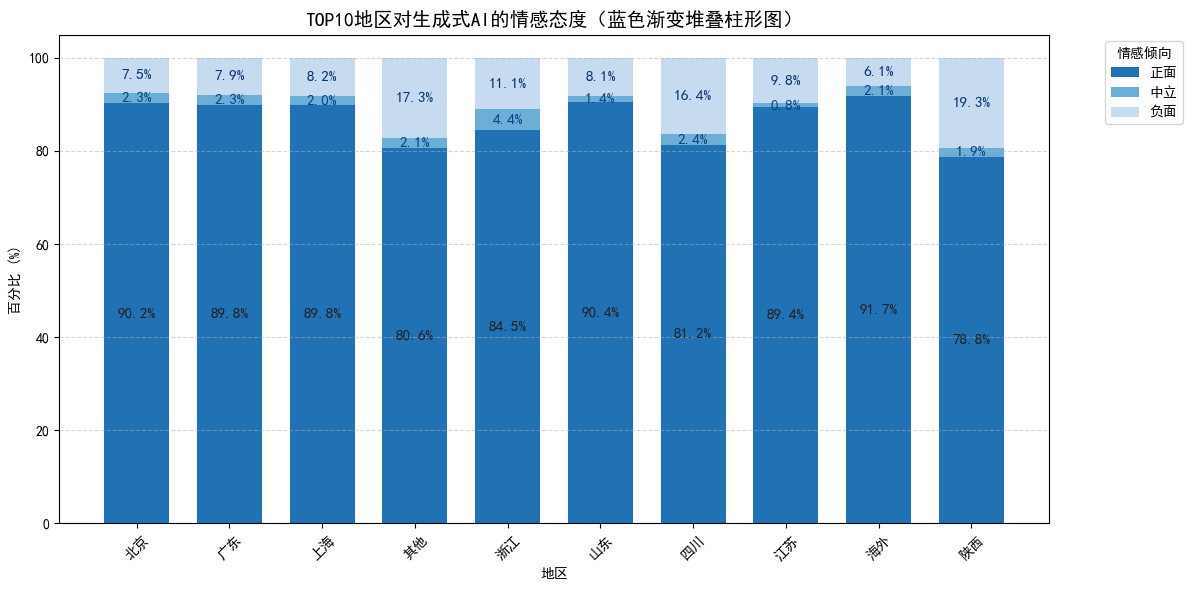

In [134]:
# 3. 地区维度分析
print("\n=== 地区维度分析（蓝色渐变堆叠柱形图，数据标签更深蓝） ===")
region_data = data[data['地区'] != '未知地区'].copy()

if len(region_data) > 0:
    region_sentiment = pd.crosstab(region_data['地区'], region_data['情感倾向'])
    region_main_sentiment = region_sentiment.idxmax(axis=1)
    region_positive_rate = (region_sentiment['正面'] / region_sentiment.sum(axis=1) * 100).round(1)
    
    # 准备地图可视化数据
    region_stats = pd.DataFrame({
        '地区': region_positive_rate.index,
        '正面情感比例': region_positive_rate.values,
        '主要情感': region_main_sentiment.values
    })
    
    # 条形图展示TOP10地区
    top_regions = region_data['地区'].value_counts().head(10).index
    top_region_sentiment = pd.crosstab(
        region_data[region_data['地区'].isin(top_regions)]['地区'], 
        region_data[region_data['地区'].isin(top_regions)]['情感倾向'], 
        normalize='index'
    ) * 100

    import matplotlib
    import numpy as np

    emotions = ['正面', '中立', '负面']
    x = np.arange(len(top_regions))
    width = 0.7

    blues = matplotlib.cm.get_cmap('Blues', len(emotions)+2)
    bar_colors = [matplotlib.colors.rgb2hex(blues(i/(len(emotions)+1))) for i in range(len(emotions), 0, -1)]
    label_blues = matplotlib.cm.get_cmap('Blues', 256)
    label_colors = [
        '#222222',  # 正面
        matplotlib.colors.rgb2hex(label_blues(0.92)),  # 中立
        matplotlib.colors.rgb2hex(label_blues(0.98)),  # 负面
    ]

    fig, ax = plt.subplots(figsize=(12, 6))
    bottom = np.zeros(len(top_regions))
    barlist = []
    for i, emo in enumerate(emotions):
        vals = top_region_sentiment[emo].values if emo in top_region_sentiment.columns else np.zeros(len(top_regions))
        bars = ax.bar(x, vals, width, bottom=bottom, color=bar_colors[i], label=emo)
        barlist.append((bars, bottom.copy(), vals, label_colors[i]))
        bottom += vals

    # 添加更深蓝色数据标签
    for bars, bottoms, vals, txt_color in barlist:
        for rect, b, v in zip(bars, bottoms, vals):
            if v > 0.5:
                ax.text(
                    rect.get_x() + rect.get_width()/2, b + v/2, f"{v:.1f}%",
                    ha='center', va='center', fontsize=11, color=txt_color, fontweight='bold'
                )

    ax.set_xticks(x)
    ax.set_xticklabels(top_regions, rotation=45)
    ax.set_xlabel('地区')
    ax.set_ylabel('百分比 (%)')
    ax.set_title('TOP10地区对生成式AI的情感态度（蓝色渐变堆叠柱形图）', fontsize=14)
    ax.legend(title='情感倾向', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [12]:
region_data = data[data['地区'] != '未知地区'].copy()
if len(region_data) > 0:
    region_sentiment = pd.crosstab(region_data['地区'], region_data['情感倾向'], normalize='index') * 100
    region_main_sentiment = region_sentiment.idxmax(axis=1)
    print("省份\t正面(%)\t中立(%)\t负面(%)\t主导情感")
    for province in region_sentiment.index:
        pos = region_sentiment.loc[province].get('正面', 0)
        neu = region_sentiment.loc[province].get('中立', 0)
        neg = region_sentiment.loc[province].get('负面', 0)
        main = region_main_sentiment.loc[province]
        print(f"{province}\t{pos:.1f}\t{neu:.1f}\t{neg:.1f}\t{main}")

省份	正面(%)	中立(%)	负面(%)	主导情感
上海	90.2	2.3	7.5	正面
云南	80.5	1.6	17.9	正面
其他	89.8	2.3	7.9	正面
内蒙古	76.7	1.7	21.7	正面
北京	89.8	2.0	8.2	正面
台湾	77.5	5.0	17.5	正面
吉林	61.8	8.8	29.4	正面
四川	80.6	2.1	17.3	正面
天津	90.0	0.8	9.2	正面
宁夏	83.3	0.0	16.7	正面
安徽	78.8	1.9	19.2	正面
山东	84.5	4.4	11.1	正面
山西	75.5	0.0	24.5	正面
广东	90.4	1.4	8.1	正面
广西	84.2	0.0	15.8	正面
新疆	80.0	0.0	20.0	正面
江苏	81.2	2.4	16.4	正面
江西	74.7	3.3	22.0	正面
河北	77.7	3.1	19.2	正面
河南	81.4	2.7	15.9	正面
浙江	89.4	0.8	9.8	正面
海南	85.0	3.3	11.7	正面
海外	91.7	2.1	6.1	正面
湖北	86.5	3.1	10.4	正面
湖南	77.0	2.2	20.9	正面
澳门	83.3	0.0	16.7	正面
甘肃	74.0	2.7	23.3	正面
福建	90.9	2.2	6.9	正面
美国	86.2	3.2	10.6	正面
西藏	100.0	0.0	0.0	正面
贵州	78.9	1.1	20.0	正面
辽宁	83.8	0.0	16.2	正面
重庆	86.2	2.8	11.0	正面
陕西	78.8	1.9	19.3	正面
青海	86.7	6.7	6.7	正面
香港	87.9	1.9	10.2	正面
黑龙江	84.8	1.5	13.6	正面


<Figure size 1200x1000 with 0 Axes>

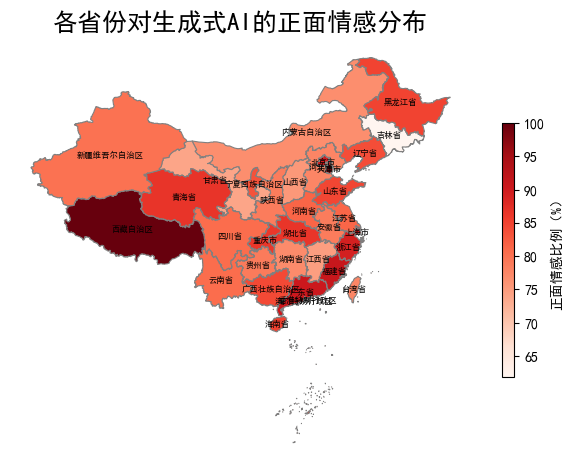

In [13]:
# 静态中国地图：正面情感比例可视化
import geopandas as gpd
import matplotlib.pyplot as plt

# 读取中国省份shapefile
china_map = gpd.read_file('china_provinces.shp',encoding='utf-8')
region_stats['地区'] = region_stats['地区'].replace({
    '北京': '北京市',
    '山东': '山东省',
    '广东': '广东省',
    '上海': '上海市',
    '江苏': '江苏省',
    '海南': '海南省',
    '天津': '天津市',
    '四川': '四川省',
    '香港': '香港特别行政区',
    '河北': '河北省',
    '福建': '福建省',
    '陕西': '陕西省',
    '安徽': '安徽省',
    '澳门': '澳门特别行政区',
    '内蒙古': '内蒙古自治区',
    '湖北': '湖北省',
    '浙江': '浙江省',
    '云南': '云南省',
    '江西': '江西省',
    '黑龙江': '黑龙江省',
    '广西': '广西壮族自治区',
    '湖南': '湖南省',
    '河南': '河南省',
    '山西': '山西省',
    '台湾': '台湾省',
    '吉林': '吉林省',
    '青海': '青海省',
    '甘肃': '甘肃省',
    '辽宁': '辽宁省',
    '重庆': '重庆市',
    '贵州': '贵州省',
    '宁夏': '宁夏回族自治区',
    '新疆': '新疆维吾尔自治区',
    '西藏': '西藏自治区'
})

# 合并情感比例数据
china_map = china_map.merge(region_stats[['地区', '正面情感比例']], left_on='name', right_on='地区', how='left')

plt.figure(figsize=(12, 10))
ax = china_map.plot(
    column='正面情感比例',
    cmap='Reds',
    linewidth=0.8,
    edgecolor='gray',
    legend=True,
    legend_kwds={'label': "正面情感比例（%）", 'shrink': 0.6}
)
plt.title('各省份对生成式AI的正面情感分布', fontsize=18)
plt.axis('off')

# 标注省份名称
for idx, row in china_map.iterrows():
    geom = row['geometry']
    if geom.geom_type == 'MultiPolygon':
        largest = max(geom.geoms, key=lambda a: a.area)
        x, y = largest.centroid.x, largest.centroid.y
    else:
        x, y = geom.centroid.x, geom.centroid.y
    plt.text(x, y, row['name'], fontsize=6, ha='center', va='center', color='black')

plt.tight_layout()
plt.show()

In [ ]:
# 4. 设备维度分析（收入水平）
try:
    device_price = pd.read_csv('设备价格.txt', sep='\t', encoding='utf-8', names=['设备', '价格'])
    device_price['价格'] = pd.to_numeric(device_price['价格'], errors='coerce')
    device_data = data[data['设备'] != '未知设备'].copy()
    
    # 合并价格信息
    device_data = device_data.merge(device_price, left_on='设备', right_on='设备', how='left')
    device_data = device_data[device_data['价格'].notna()]
    
    # 定义收入水平
    def get_income_level(price):
        if price < 2000:
            return '低收入群体(设备<2000元)'
        elif price < 5000:
            return '中等收入群体(设备2000-5000元)'
        else:
            return '高收入群体(设备>5000元)'
    
    device_data['收入水平'] = device_data['价格'].apply(get_income_level)
    
    # 分析收入水平与情感的关系
    income_sentiment = pd.crosstab(device_data['收入水平'], device_data['情感倾向'], normalize='index') * 100
    
    
    # 设备品牌分析
    device_data['品牌'] = device_data['设备'].str.extract(r'(华为|苹果|iPhone|小米|OPPO|vivo|三星|荣耀|真我)')
    brand_sentiment = pd.crosstab(
        device_data[device_data['品牌'].notna()]['品牌'], 
        device_data[device_data['品牌'].notna()]['情感倾向'],
        normalize='index'
    ) * 100
    
    
except Exception as e:
    print(f"设备价格文件读取失败: {e}")

In [103]:
# 旭日图：收入水平-品牌-情感倾向（品牌层蓝色渐变，深蓝到浅蓝）
import plotly.express as px
import matplotlib

brand_labels = ['三星', '华为', '荣耀', 'iPhone', '小米', 'vivo', 'OPPO', '真我']
sunburst_df = device_data[device_data['品牌'].isin(brand_labels) & device_data['情感倾向'].notna()]

# 生成蓝色渐变（深蓝到浅蓝）
blues = matplotlib.cm.get_cmap('Blues', len(brand_labels)+2)
brand_blues = [matplotlib.colors.rgb2hex(blues(i/(len(brand_labels)+1))) for i in range(len(brand_labels), 0, -1)]

brand_color_map = {brand: color for brand, color in zip(brand_labels, brand_blues)}

# 收入水平自定义颜色
income_color_map = {
    '低收入群体(设备<2000元)': '#B0E0E6',   # 浅蓝
    '中等收入群体(设备2000-5000元)': '#87CEEB', # 天蓝
    '高收入群体(设备>5000元)': '#4682B4',   # 深蓝
}

# 情感倾向颜色
emotion_color_map = {
    '正面': '#339966',   # 绿色
    '中立': '#ffcc00',   # 黄色
    '负面': '#ff4444'    # 红色
}

# 合并所有颜色映射
all_color_map = {}
all_color_map.update(brand_color_map)
all_color_map.update(income_color_map)
all_color_map.update(emotion_color_map)

fig = px.sunburst(
    sunburst_df,
    path=['收入水平', '品牌', '情感倾向'],
    color='品牌',
    color_discrete_map=all_color_map,
    title='设备收入水平-品牌-情感分布旭日图（品牌蓝色渐变）'
)
fig.update_traces(textinfo='label+percent entry')
fig.show()

C:\Users\fwq81\AppData\Local\Temp\ipykernel_9044\3493857674.py:9: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.



In [102]:
# 旭日图：收入水平-品牌-情感倾向
import plotly.express as px

# 确保已生成 device_data 并提取品牌
device_data['品牌'] = device_data['设备'].str.extract(r'(华为|苹果|iPhone|小米|OPPO|vivo|三星|荣耀|真我)')

# 只保留有品牌和情感的数据
sunburst_df = device_data[device_data['品牌'].notna() & device_data['情感倾向'].notna()]

color_map = {
    '正面': '#339966',   # 绿色
    '中立': '#ffcc00',   # 黄色
    '负面': '#ff4444'    # 红色
}

fig = px.sunburst(
    sunburst_df,
    path=['收入水平', '品牌', '情感倾向'],
    color='品牌',
    color_discrete_map=all_color_map,
    title='设备收入水平-品牌-情感分布旭日图（品牌蓝色渐变）',
    width=900,   # 图宽度
    height=900   # 图高度
)
fig.update_traces(textinfo='label+percent entry')
fig.show()

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.



In [104]:
import plotly.express as px
import matplotlib

brand_labels = ['三星', '华为', '荣耀', 'iPhone', '小米', 'vivo', 'OPPO', '真我']
sunburst_df = device_data[device_data['品牌'].isin(brand_labels) & device_data['情感倾向'].notna()]

# 生成蓝色渐变（深蓝到浅蓝）
blues = matplotlib.cm.get_cmap('Blues', len(brand_labels)+2)
brand_blues = [matplotlib.colors.rgb2hex(blues(i/(len(brand_labels)+1))) for i in range(len(brand_labels), 0, -1)]
brand_color_map = {brand: color for brand, color in zip(brand_labels, brand_blues)}

# 收入水平自定义颜色
income_color_map = {
    '低收入群体(设备<2000元)': '#B0E0E6',   # 浅蓝
    '中等收入群体(设备2000-5000元)': '#87CEEB', # 天蓝
    '高收入群体(设备>5000元)': '#4682B4',   # 深蓝
}

# 情感倾向颜色
emotion_color_map = {
    '正面': '#339966',   # 绿色
    '中立': '#ffcc00',   # 黄色
    '负面': '#ff4444'    # 红色
}

# 1. 收入水平-情感分布旭日图
income_color_map_full = income_color_map.copy()
income_color_map_full.update(emotion_color_map)
fig1 = px.sunburst(
    device_data[device_data['情感倾向'].notna()],
    path=['收入水平', '情感倾向'],
    color='收入水平',
    color_discrete_map=income_color_map_full,
    title='设备收入水平-情感分布旭日图',
    width=700,
    height=700
)
fig1.update_traces(textinfo='label+percent entry')
fig1.show()

# 2. 品牌-情感分布旭日图
brand_color_map_full = brand_color_map.copy()
brand_color_map_full.update(emotion_color_map)
fig2 = px.sunburst(
    sunburst_df,
    path=['品牌', '情感倾向'],
    color='品牌',
    color_discrete_map=brand_color_map_full,
    title='品牌-情感分布旭日图',
    width=700,
    height=700
)
fig2.update_traces(textinfo='label+percent entry')
fig2.show()

C:\Users\fwq81\AppData\Local\Temp\ipykernel_9044\2719167345.py:8: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.



d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.

d:\anaconda\Lib\site-packages\plotly\io\_renderers.py:395: DeprecationWarning:

distutils Version classes are deprecated. Use packaging.version instead.



In [121]:
print("\n=== 交叉分析：性别×情感×地区 ===")
cross_data = data[(data['性别'] != '未知') & (data['地区'] != '未知地区')]
if len(cross_data) > 0:
    for gender in cross_data['性别'].unique():
        gender_subset = cross_data[cross_data['性别'] == gender]
        print(f"\n{gender}性用户的地区情感分布:")
        gender_region_sentiment = pd.crosstab(
            gender_subset['地区'], 
            gender_subset['情感倾向'],
            normalize='index'
        ) * 100
        print(gender_region_sentiment.head())


=== 交叉分析：性别×情感×地区 ===

男性用户的地区情感分布:
情感倾向        中立         正面         负面
地区                                  
上海    2.234206  89.830508   7.935285
云南    2.325581  80.232558  17.441860
其他    1.827676  90.078329   8.093995
内蒙古   2.173913  78.260870  19.565217
北京    1.985112  89.503722   8.511166

女性用户的地区情感分布:
情感倾向        中立         正面         负面
地区                                  
上海    2.348993  91.946309   5.704698
云南    0.000000  81.081081  18.918919
其他    2.722063  89.541547   7.736390
内蒙古   0.000000  71.428571  28.571429
北京    2.228826  90.564636   7.206538



=== 性别×情感×地区交叉分布（堆叠柱形图，蓝色渐变，无透视表） ===


C:\Users\fwq81\AppData\Local\Temp\ipykernel_9044\3749855660.py:34: MatplotlibDeprecationWarning:

The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.



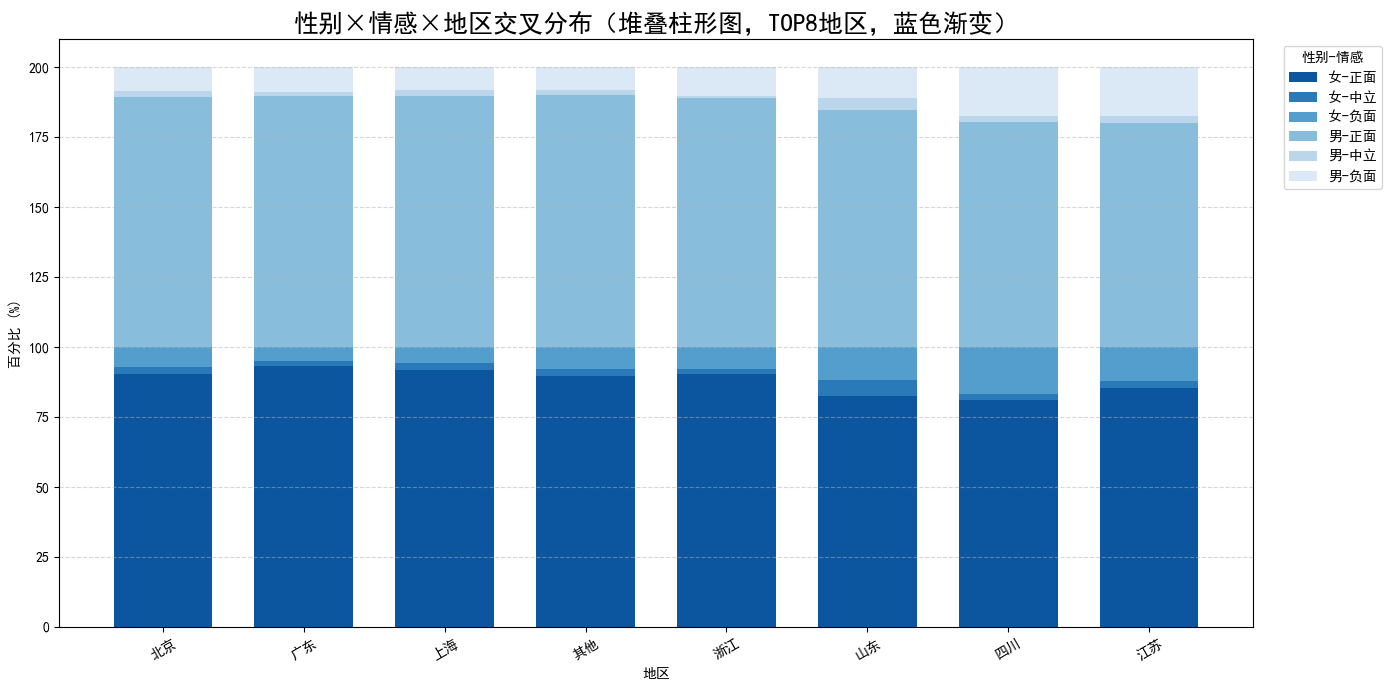

In [124]:
import matplotlib.pyplot as plt
import matplotlib
import numpy as np

print("\n=== 性别×情感×地区交叉分布（堆叠柱形图，蓝色渐变，无透视表） ===")
cross_data = data[(data['性别'] != '未知') & (data['地区'] != '未知地区')]
if len(cross_data) > 0:
    # 选取评论数最多的前8个地区
    top_regions = cross_data['地区'].value_counts().head(8).index.tolist()
    plot_df = cross_data[cross_data['地区'].isin(top_regions)].copy()
    genders = sorted(plot_df['性别'].unique())
    emotions = ['正面', '中立', '负面']

    # 构造所有组合的百分比矩阵
    bar_labels = []
    bar_values = []
    for gender in genders:
        for emo in emotions:
            bar_labels.append(f"{gender}-{emo}")
            vals = []
            for region in top_regions:
                subset = plot_df[(plot_df['性别'] == gender) & (plot_df['情感倾向'] == emo) & (plot_df['地区'] == region)]
                total = plot_df[(plot_df['性别'] == gender) & (plot_df['地区'] == region)].shape[0]
                percent = 100 * len(subset) / total if total > 0 else 0
                vals.append(percent)
            bar_values.append(vals)
    bar_values = np.array(bar_values)  # shape: (n_bars, n_regions)

    x = np.arange(len(top_regions))
    width = 0.7

    # 生成蓝色渐变色
    n_bars = len(bar_labels)
    blues = matplotlib.cm.get_cmap('Blues', n_bars+2)
    bar_colors = [matplotlib.colors.rgb2hex(blues(i/(n_bars+1))) for i in range(n_bars, 0, -1)]

    # 手动堆叠
    fig, ax = plt.subplots(figsize=(14, 7))
    bottom = np.zeros(len(top_regions))
    for i in range(n_bars):
        ax.bar(x, bar_values[i], width, bottom=bottom, color=bar_colors[i], label=bar_labels[i])
        bottom += bar_values[i]

    ax.set_xticks(x)
    ax.set_xticklabels(top_regions, rotation=30)
    ax.set_xlabel("地区")
    ax.set_ylabel("百分比 (%)")
    ax.grid(True, axis='y', linestyle='--', alpha=0.5)
    ax.set_title("性别×情感×地区交叉分布（堆叠柱形图，TOP8地区，蓝色渐变）", fontsize=18)
    ax.legend(title="性别-情感", bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()